In [1]:
from langchain_groq import ChatGroq
from langchain.tools import tool
from langchain.agents import create_agent
import os
from dotenv import load_dotenv
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain.messages import HumanMessage,AIMessage,SystemMessage

load_dotenv()

os.environ['GROQ_API_KEY']=os.getenv('GROQ_API_KEY')

In [2]:
llm=ChatGroq(model='openai/gpt-oss-120b')

In [3]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.6', 'langchain': '1.4.3'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001AC0F2FDC70>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001AC0F42ECC0>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [4]:
from langchain_community.utilities import SQLDatabase
from langchain_community.agent_toolkits import create_sql_agent

#connect sqllit db
db = SQLDatabase.from_uri(
    "sqlite:///E:/chatbot/chat_with_db/student.db"
)


print("Database connected!")
print("Tables:", db.get_usable_table_names())

C:\Users\Azrap\AppData\Local\Temp\ipykernel_19056\3590907073.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.utilities import SQLDatabase


Database connected!
Tables: ['students']


In [5]:
agent=create_sql_agent(
    llm=llm,
    db=db,
    agent_type='tool-calling',
    verbose=True
)

In [6]:
agent

AgentExecutor(name='SQL Agent Executor', verbose=True, agent=RunnableMultiActionAgent(runnable=RunnableAssign(mapper={
  agent_scratchpad: RunnableLambda(lambda x: message_formatter(x['intermediate_steps']))
})
| ChatPromptTemplate(input_variables=['agent_scratchpad', 'input'], input_types={'agent_scratchpad': list[typing.Annotated[typing.Union[typing.Annotated[langchain_core.messages.ai.AIMessage, Tag(tag='ai')], typing.Annotated[langchain_core.messages.human.HumanMessage, Tag(tag='human')], typing.Annotated[langchain_core.messages.chat.ChatMessage, Tag(tag='chat')], typing.Annotated[langchain_core.messages.system.SystemMessage, Tag(tag='system')], typing.Annotated[langchain_core.messages.function.FunctionMessage, Tag(tag='function')], typing.Annotated[langchain_core.messages.tool.ToolMessage, Tag(tag='tool')], typing.Annotated[langchain_core.messages.ai.AIMessageChunk, Tag(tag='AIMessageChunk')], typing.Annotated[langchain_core.messages.human.HumanMessageChunk, Tag(tag='HumanMessageC

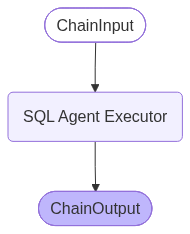

In [8]:

# Visualize the graph

from IPython.display import Image, display

display(
    Image(
        agent.get_graph().draw_mermaid_png()
    )
)


In [11]:
print("Database URI:", db)
print("Total records:", db.run("SELECT COUNT(*) FROM students"))
print("All students:", db.run("SELECT * FROM students"))

Database URI: <langchain_community.utilities.sql_database.SQLDatabase object at 0x000001AC0F7541D0>
Total records: [(8,)]
All students: [(1, 'Azra', 12), (2, 'Ayesha', 10), (3, 'Rahul', 11), (4, 'Sara', 12), (5, 'Aman', 10), (6, 'Priya', 11), (7, 'Zoya', 12), (8, 'Rohan', 9)]


In [12]:
response = agent.invoke({
    "input": "Run SELECT COUNT(*) FROM students. Use the actual query result to answer. Do not infer the count from a preview of the table."
})

print(response["output"])



> Entering new SQL Agent Executor chain...

Invoking: `sql_db_list_tables` with `{'tool_input': ''}`


students
Invoking: `sql_db_schema` with `{'table_names': 'students'}`



CREATE TABLE students (
	"ID" INTEGER, 
	name VARCHAR(100), 
	class INTEGER, 
	PRIMARY KEY ("ID")
)

/*
3 rows from students table:
ID	name	class
1	Azra	12
2	Ayesha	10
3	Rahul	11
*/
Invoking: `sql_db_query_checker` with `{'query': 'SELECT COUNT(*) FROM students;'}`


SELECT COUNT(*) FROM students;
Invoking: `sql_db_query` with `{'query': 'SELECT COUNT(*) FROM students;'}`


[(8,)]The query returns a count of **8** rows in the **students** table.

> Finished chain.
The query returns a count of **8** rows in the **students** table.


In [13]:
response = agent.invoke({
    "input": "Tell me the total number of rows and columns in the students table.Use SQL queries to calculate both values."
})

print(response["output"])



> Entering new SQL Agent Executor chain...

Invoking: `sql_db_list_tables` with `{'tool_input': ''}`


students
Invoking: `sql_db_schema` with `{'table_names': 'students'}`



CREATE TABLE students (
	"ID" INTEGER, 
	name VARCHAR(100), 
	class INTEGER, 
	PRIMARY KEY ("ID")
)

/*
3 rows from students table:
ID	name	class
1	Azra	12
2	Ayesha	10
3	Rahul	11
*/
Invoking: `sql_db_query_checker` with `{'query': 'SELECT COUNT(*) AS row_count FROM students;'}`


SELECT COUNT(*) AS row_count FROM students;
Invoking: `sql_db_query` with `{'query': 'SELECT COUNT(*) AS row_count FROM students;'}`


[(8,)]
Invoking: `sql_db_query_checker` with `{'query': "SELECT COUNT(*) AS col_count FROM pragma_table_info('students');"}`


SELECT COUNT(*) AS col_count FROM pragma_table_info('students');
Invoking: `sql_db_query` with `{'query': "SELECT COUNT(*) AS col_count FROM pragma_table_info('students');"}`


[(3,)]**Total rows in `students` table:** 8  
**Total columns in `students` table:** 3

> Finished cha

In [14]:

while True:
    question = input("YOU: ").strip()

    if question.lower() == "exit":
        print("BOT: Goodbye!")
        break

    if not question:
        continue

    try:
        response = agent.invoke({"input": question})
        print("\nBOT:", response["output"], "\n")

    except Exception as e:
        print("Error:", e)



> Entering new SQL Agent Executor chain...

Invoking: `sql_db_list_tables` with `{'tool_input': ''}`


students
Invoking: `sql_db_schema` with `{'table_names': 'students'}`



CREATE TABLE students (
	"ID" INTEGER, 
	name VARCHAR(100), 
	class INTEGER, 
	PRIMARY KEY ("ID")
)

/*
3 rows from students table:
ID	name	class
1	Azra	12
2	Ayesha	10
3	Rahul	11
*/
Invoking: `sql_db_query_checker` with `{'query': 'SELECT ID, name, class FROM students LIMIT 10;'}`


SELECT ID, name, class FROM students LIMIT 10;
Invoking: `sql_db_query` with `{'query': 'SELECT ID, name, class FROM students LIMIT 10;'}`


[(1, 'Azra', 12), (2, 'Ayesha', 10), (3, 'Rahul', 11), (4, 'Sara', 12), (5, 'Aman', 10), (6, 'Priya', 11), (7, 'Zoya', 12), (8, 'Rohan', 9)]Here are the students in the database:

| ID | Name   | Class |
|----|--------|-------|
| 1  | Azra   | 12 |
| 2  | Ayesha | 10 |
| 3  | Rahul  | 11 |
| 4  | Sara   | 12 |
| 5  | Aman   | 10 |
| 6  | Priya  | 11 |
| 7  | Zoya   | 12 |
| 8  | Rohan  | 9 |

>